# BARCLEY'S BANKS CHURN ANALYSIS

### Project objective
- Barclays Bank Facing high Customer churn rate, and, customer not keep using services, being a Data scientist your task is to identify the companies problem so that they can get the real time insights and management can take decision accordingly, Previously banks were not getting timely insightsand did not take decisions timely, that costs high customer churn rate, the previous methodologies were old and not upto dated, presently bank need live analysis and corrective measures to predict the future churn rates and live analysis

#### Step 1 - Import necessary libraries 

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, recall_score
import pickle
import IPython as ip
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
import warnings
warnings.filterwarnings('ignore')
print("All Modules Loaded Successfully !! ")


All Modules Loaded Successfully !! 


#### Step 2 - Load Datasets

In [ ]:
url = "data/ActiveCustomer.csv"
active_customer_df = pd.read_csv(url)
print("Done")

In [ ]:
url = "data/CreditCard.csv"
credit_card_df = pd.read_csv(url)
print("Done")

In [ ]:
url = "data/ExitCustomer.csv"
exit_customer_df = pd.read_csv(url)
print("Done")

In [ ]:
url = "data/Gender.csv"
gender_df = pd.read_csv(url)
print("Done")

In [ ]:
url = "data/Geography.csv"
geography_df = pd.read_csv(url)
print("Done")

In [ ]:
url = "data/Bank_Churn.csv"
bank_churn_df = pd.read_csv(url)
print("Done")

In [ ]:
url = "data/CustomerInfo.csv"
customer_info_df = pd.read_csv(url)
print("Done")

In [ ]:
all_df=[active_customer_df,
        credit_card_df,
        exit_customer_df,
        gender_df,
        geography_df,
        bank_churn_df,
        customer_info_df]

for i in all_df:
    print("="*50)
    display(i.sample(2))

#### Step 3 - Exploratory Data Analysis(EDA)

In [ ]:
# Step 3.1 : Show bank_churn_df sample

bank_churn_df.sample(5)

In [ ]:
# Step 3.2 : Show df shape size

bank_churn_df. shape

# 14 columns and 10k rows

In [ ]:
bank_churn_df.size

In [ ]:
# combine all the dataframes

merged_df=pd.merge(bank_churn_df,customer_info_df,on="CustomerId")
merged_df=pd.merge(merged_df,geography_df,on="GeographyID")
final_df=pd.merge(merged_df,gender_df,on="GenderID")
final_df

In [ ]:
# show column info
# step 3.4 : 

final_df.info()

In [ ]:
# Step 3.5 : Drop Nan or missing values

final_df.dropna(inplace=True)
print("Done")

In [ ]:
# step 3.6 : Show data stats

final_df.describe(include='number')

In [ ]:
# step 3.7 : Show categorical data stats

final_df.describe(include='object')

In [ ]:
# step 3.8 : Show Data correlation

corr = final_df.corr(numeric_only=True)
corr

# corr range form
# -1 to +1
# -1 : represents : Highly -negative correlation
# +1 : represents : Highly +positive correlation
# 0 : represents : no correlation

In [ ]:
# Step 3.9 : 

plt.figure(figsize = (15,15))
plt.title("Correlation Matrix")
sns.heatmap(corr, annot = True)
plt.show()

In [67]:
# Step 3.10 : Divide Columns into required objects
# NOTE - After you do run all there will be error to resolve that run this cell once more and run all the cells below this one by one

textual_columns = final_df.select_dtypes('object').columns
numerical_columns = final_df.select_dtypes('number').columns
print("Textual Columns : \n", textual_columns)
print("="*100)
print("Numerical Columns : \n", numerical_columns)

Textual Columns : 
 Index(['Surname', 'GeographyLocation', 'GenderCategory', 'Month', 'Day'], dtype='str')
Numerical Columns : 
 Index(['CustomerId', 'CreditScore', 'GeographyID', 'GenderID', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='str')


In [68]:
# Setp 3.11 : Change Bank DOJ to datetime Dtype

final_df['Bank DOJ']=pd.to_datetime(final_df['Bank DOJ'])
print("Done")

Done


In [69]:
# Step 3.12 : Drop unwanted column

final_df.drop('RowNumber', axis = 1, inplace = True)

# axis = 1: means: drop column, axis:0 : drop row
# inplace=True: means: apply changes in original dataset

print("Done")

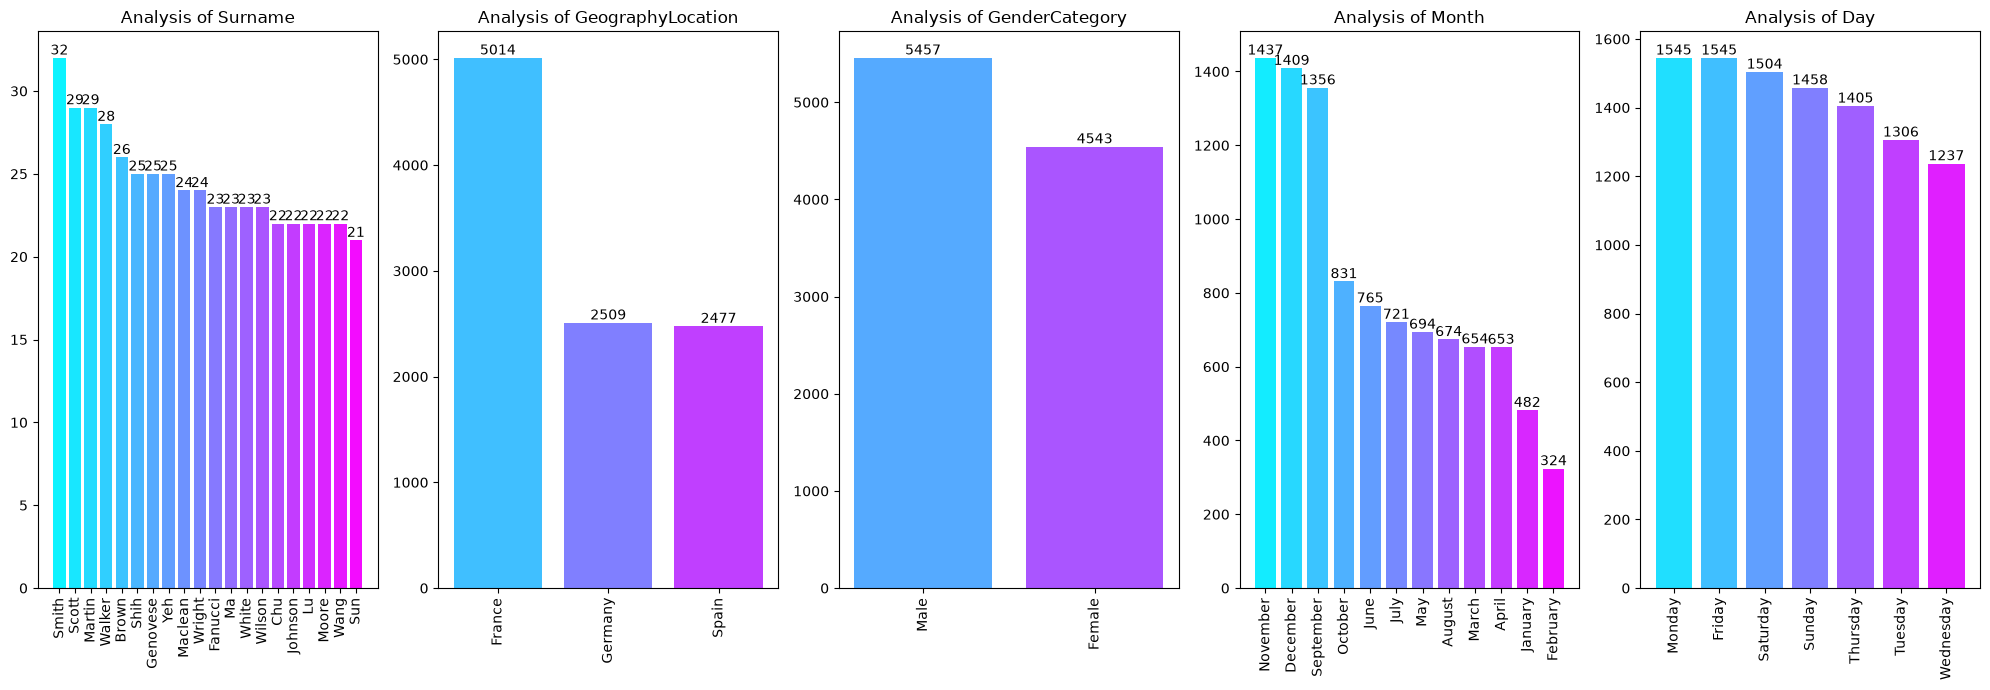

In [70]:
# 3.13 : Univariate Analysis
# means : single columns analyis

fig, axes = plt.subplots(1, len(textual_columns), figsize=(20, 7), squeeze=False)
for i, column in enumerate(textual_columns):
    temp_df = final_df[column].value_counts().head(20)
    axis = axes[0, i]
    bars = axis.bar(
        temp_df.index.astype(str),
        temp_df.values,
        color=sns.color_palette("cool", len(temp_df)),
    )
    axis.set_title(f"Analysis of {column}")
    axis.bar_label(bars)
    axis.tick_params(axis="x", labelrotation=90)
fig.tight_layout()
plt.show()

# plt.show: out of loop hai
# subplot: plot multiple plots at once
# i: is index
# j : is column name
# enumerate: to get index and value at same time
# value counts: to grouped data and count its value frequency
# sns.color_palette: to change color shades

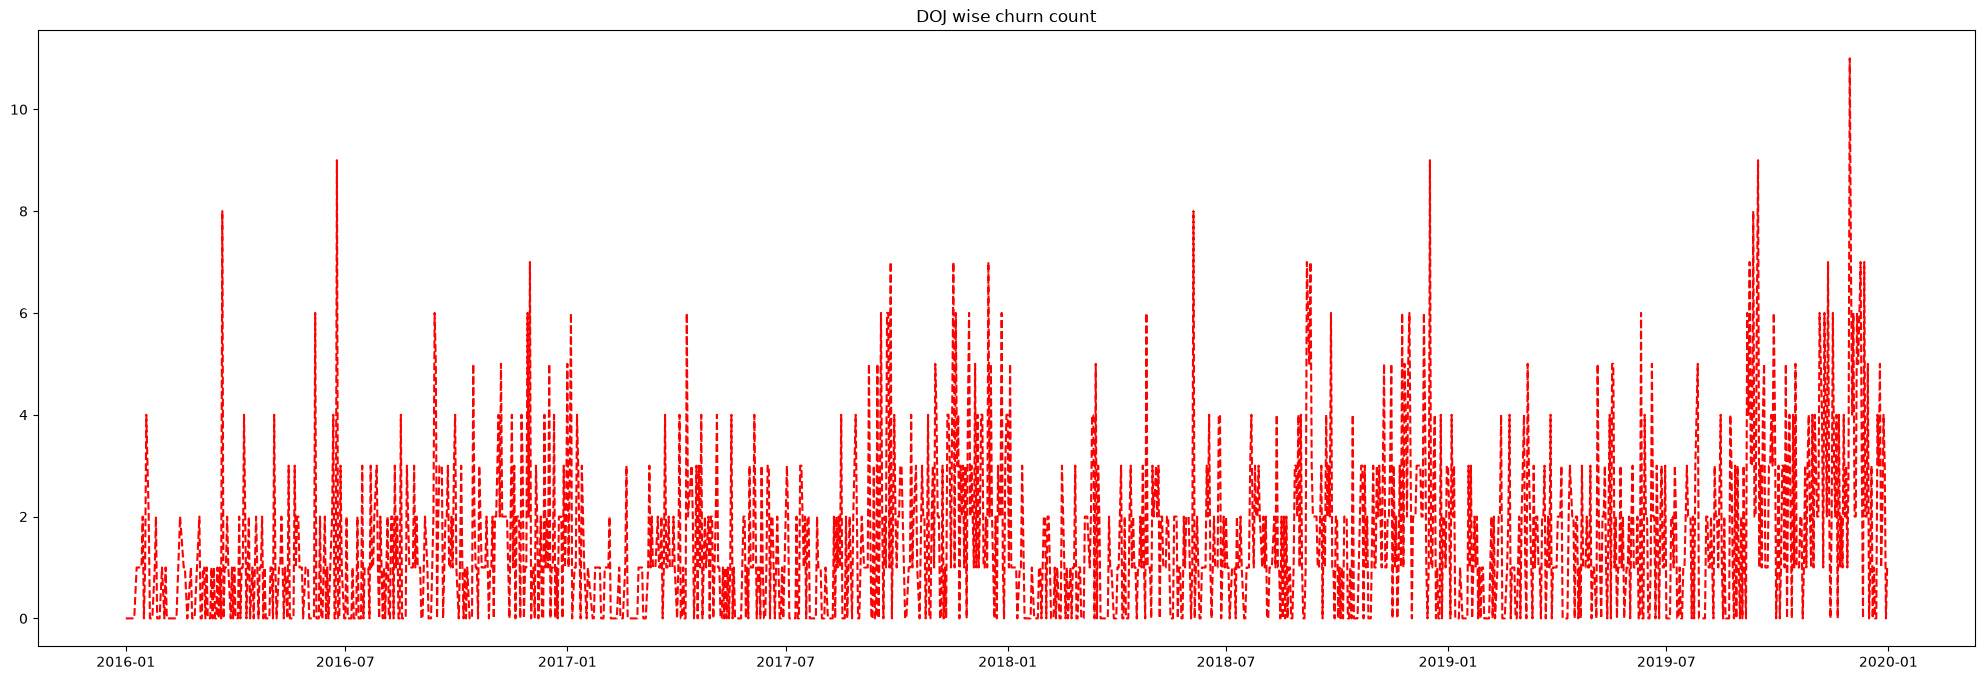

In [ ]:
# Step 3.14 : Bivariate Analysis
# Show Bank DOJ wise churn count

plt.figure(figsize = (25,8))
plt.title("DOJ wise churn count")
temp_df = final_df.groupby('Bank DOJ')['Exited'].sum()
x = temp_df.index
y = temp_df.values
plt.plot(x, y, color='r', linestyle='--')
plt.show()

In [71]:
# Step 3.15 : Create new column for monthly and weekly analysis

final_df['Month'] = final_df['Bank DOJ'].dt.month_name()
final_df['Day'] = final_df['Bank DOJ' ].dt.day_name()

# .dt : means : datetime

final_df.sample()

,CustomerId,CreditScore,GeographyID,GenderID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Bank DOJ,Surname,GeographyLocation,GenderCategory,Month,Day
8450,15710053,667,3,2,44,3,140406.68,2,0,1,57164.19,0,2019-12-15,Neumayer,Germany,Female,December,Sunday


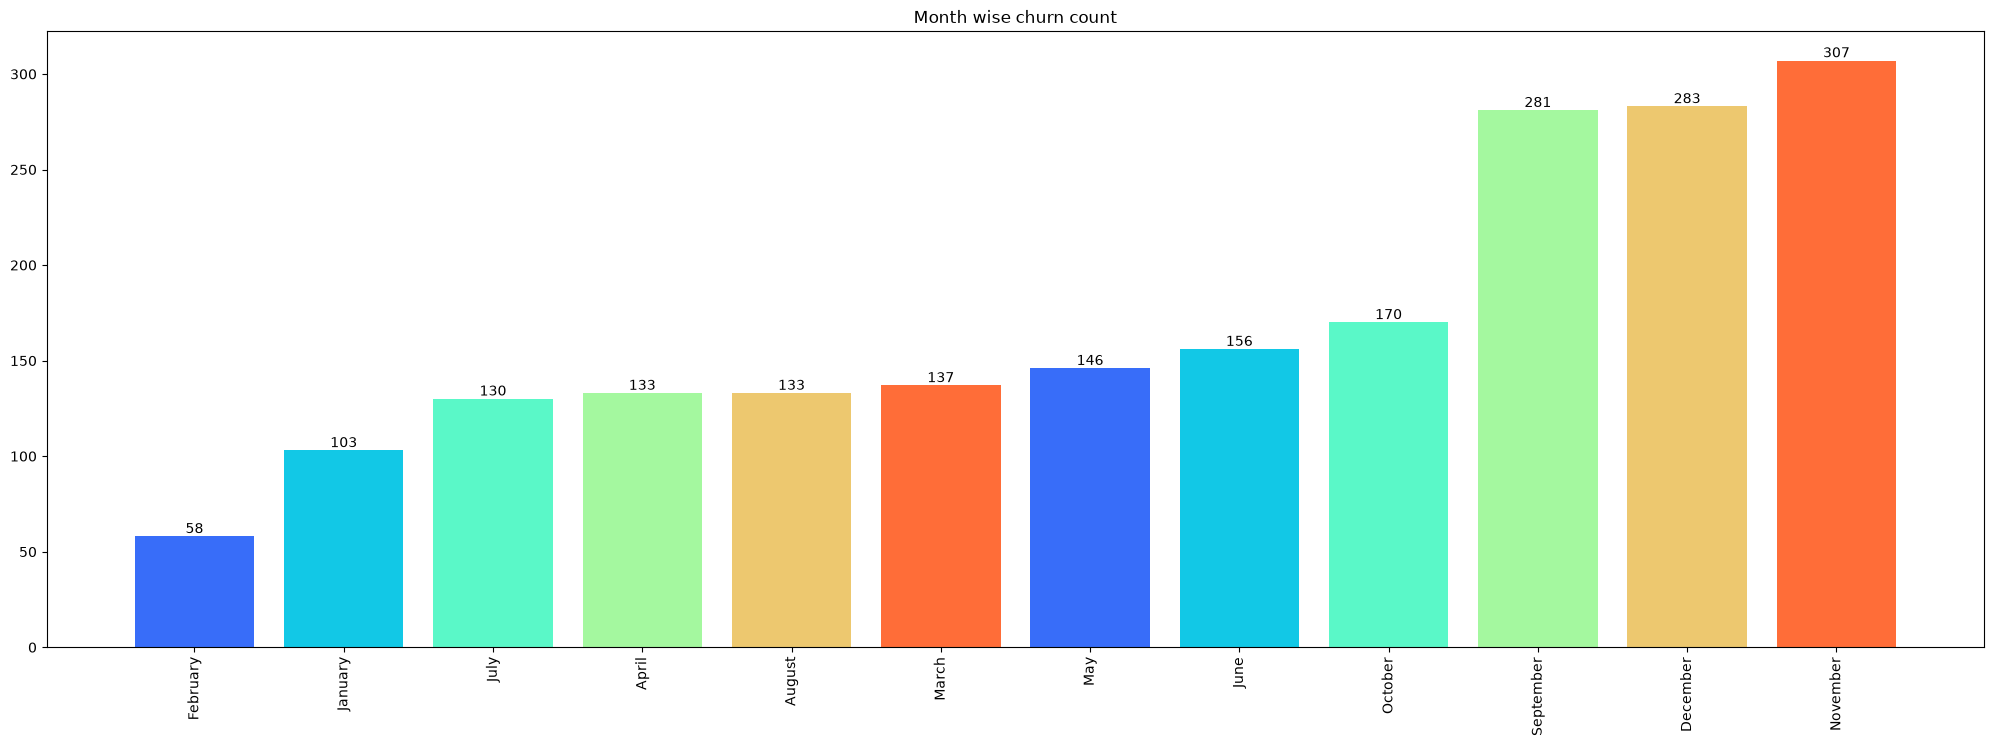

In [72]:
# step 3.16 : Show Monthly Churn Analysis

plt.figure(figsize = (25,8))
plt.title("Month wise churn count")
temp_df = final_df. groupby('Month' ) ['Exited' ]. sum().sort_values()
x = temp_df. index
y = temp_df. values
ax = plt.bar(x,y,color = sns.color_palette('rainbow' ))
plt.bar_label(ax)
plt.xticks(rotation = 90)
plt.show()

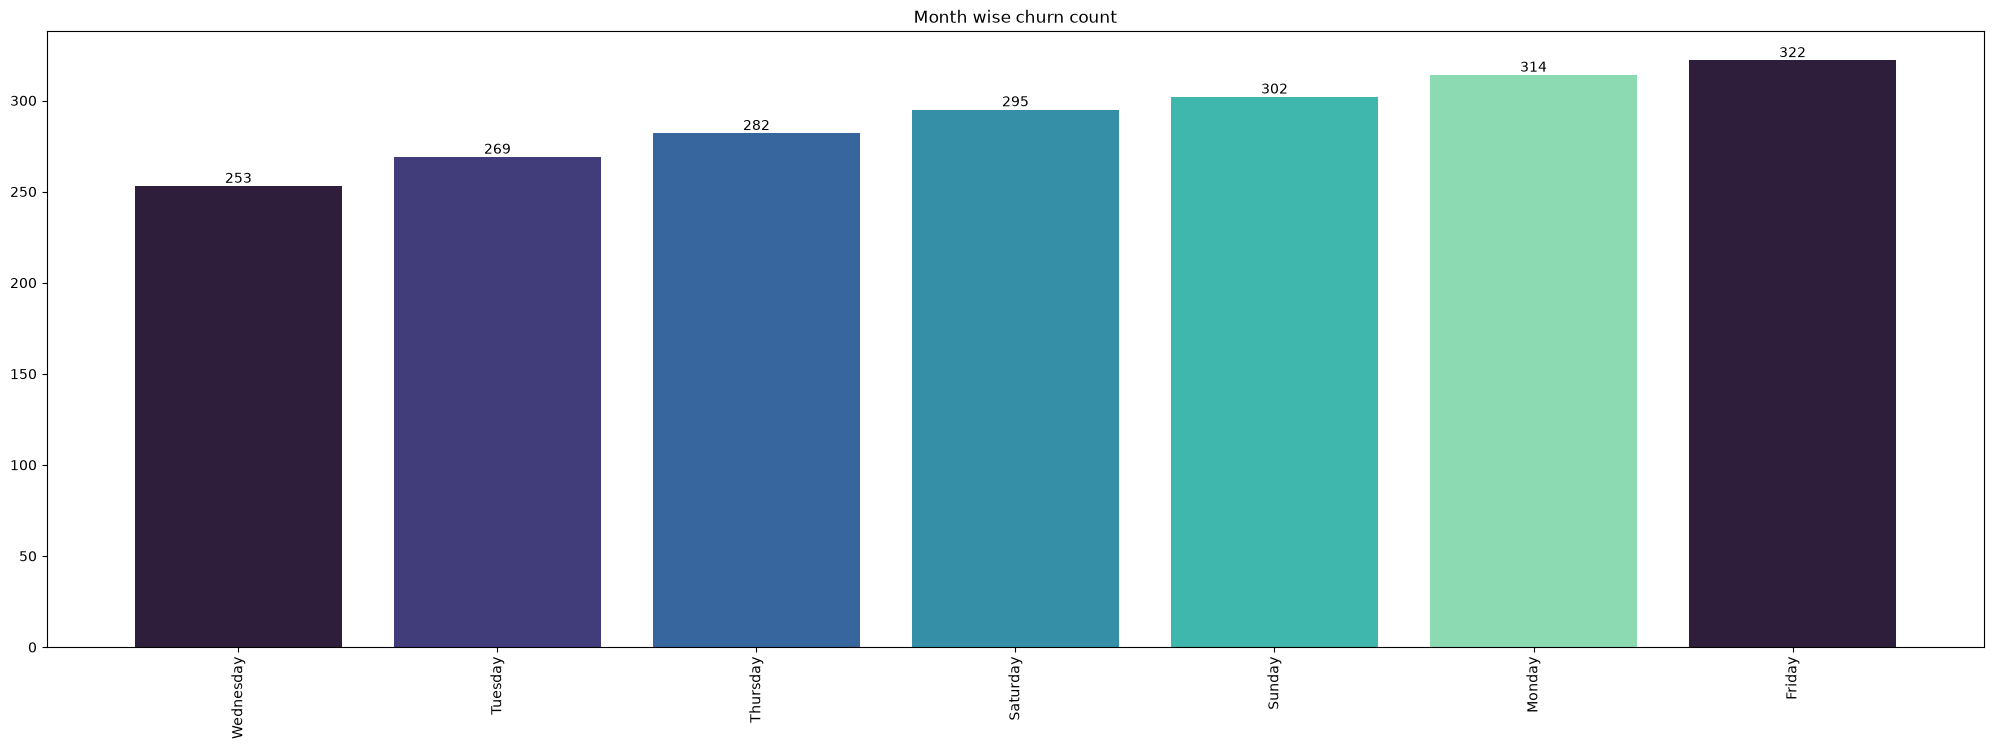

In [73]:
# step 3.17 : Show Day wise Churn Analysis
plt.figure(figsize = (25,8))
plt.title("Month wise churn count")
temp_df = final_df.groupby('Day' ) ['Exited' ]. sum() .sort_values()
x = temp_df.index
y = temp_df.values
ax = plt.bar(x,y, color = sns.color_palette('mako'))
plt.bar_label(ax)
plt.xticks(rotation = 90)
plt.show()

In [74]:
# 3.18 : gender wise Churn Analysis
# 3.19 : GeographyLocation wise churn analysis
# 3.20 : Tenure wise churn analysis

In [75]:
# step 3.21 : Remove unwanted columns for ML model
ml_drop_columns = ['CustomerId', 'GeographyID',
                    'GenderID', 'Bank DOJ',
                    'Surname', 'Day']
ml_df = final_df.drop(ml_drop_columns, axis = 1, inplace = False)
ml_df.sample()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,GeographyLocation,GenderCategory,Month
4295,476,34,5,111905.43,1,0,1,197221.81,1,Germany,Female,March


#### Step 4 : Feature Engineering
- ML onlyworks with numerical data, if we are getting any textual data
- we need to convert textual data to numerical
- Technique is called feature engineering
- Here GeographyLocation, GenderCategory or Month textual in nature

In [76]:
# Types of technique
# OHE: one hot encoding
# map: using dict
# apply lambda method
# categorical encoding
# get dummies
# ordinal encoding
# TF-IDF
# BOW: bag of words
# advance: countvectorizer, word embeddings
# more advance: vector database using cosine technique

In [77]:
# Step 4.1 : 

import calendar
months_name = list(calendar . month_name) [1: ]
index = list(range(len(months_name)))
map = dict(zip(months_name,index))

ml_df['Month'] = ml_df['Month' ].map (map)
ml_df.sample()

# zip : bind two object together and give dict
# .map : method to map the key with value

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,GeographyLocation,GenderCategory,Month
9294,713,36,7,133889.35,1,1,1,143265.65,0,France,Male,6


In [78]:
ml_df['GeographyLocation'].unique()

<StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str

In [79]:
ml_df['GenderCategory']=ml_df['GenderCategory'].map({'Male':0, 'Female':1})
ml_df['GeographyLocation' ] = ml_df['GeographyLocation'].map({'France' : 0, 'Spain' : 1, 'Germany' : 2})
ml_df.sample()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,GeographyLocation,GenderCategory,Month
8920,570,36,7,0.0,2,1,0,92118.75,0,0,1,2


In [80]:
# Step 4.2 : Show target vs feature corr
ml_df.corr()['Exited' ].sort_values(ascending = False)

Exited               1.000000
Age                  0.285323
GeographyLocation    0.153771
Balance              0.118533
GenderCategory       0.106512
EstimatedSalary      0.012097
Month                0.002312
Tenure               0.000699
HasCrCard           -0.007138
CreditScore         -0.027094
NumOfProducts       -0.047820
IsActiveMember      -0.156128
Name: Exited, dtype: float64

#### Step 5 : Divide Data into features vs target

In [84]:
X = ml_df.drop('Exited', axis=1)
y = ml_df['Exited']

# X : must be capital and in DataFrame
# y : must be small and in Series

print(X.shape)
print(y.shape)

(10000, 11)
(10000,)


#### Step 6 : Divide the data into train and test

In [85]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train-Shape: ", X_train.shape)
print("X_test-Shape: ", X_test.shape)
print("y_train-Shape: ", y_train.shape)
print("y_test-Shape: ", y_test.shape)

X_train-Shape:  (8000, 11)
X_test-Shape:  (2000, 11)
y_train-Shape:  (8000,)
y_test-Shape:  (2000,)
